# Probability, Distributions & Sample Means

**Session 15 · Part 2 study guide** · Python · pandas · NumPy · SciPy · seaborn · Capital Bikeshare data

In Part 1 we described the 731 recorded days: what one row is, how the days were selected, and the centre and spread of daily rentals. Part 2 picks up after the break and asks three new questions about the same days.

**The business setting.** Imagine you run operations for the Capital Bikeshare system in Washington, D.C. Every evening you decide how many rebalancing trucks, repair crews and bikes to have ready for tomorrow. You need to answer three questions:

| Part | Question for the operations manager | Key tools |
| --- | --- | --- |
| 7 Probability | How often is a day busy, and does that change with the type of day or the weather? | events, conditional probability, independence |
| 8 Distributions | What does the full range of days look like, and which days are unusual? | box plots, violin plots, the normal curve, z-scores |
| 9 Sample means | How far can I trust an average worked out from a few days? | the Central Limit Theorem, by simulation |
| 10 Claims | What can I honestly report to management? | the analyst's note |

Every number and chart below was produced by running the code on `day.csv`. Each result is followed by a **Business meaning** box that says what it tells a decision-maker.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

days = pd.read_csv("day.csv", parse_dates=["dteday"])
cnt = days["cnt"]                       # total rentals per day: our main variable

print(days.shape, "| from", days["dteday"].min().date(), "to", days["dteday"].max().date())
print(f"mean {cnt.mean():,.0f} | median {cnt.median():,.0f} | SD {cnt.std(ddof=0):,.0f}")

(731, 16) | from 2011-01-01 to 2012-12-31
mean 4,504 | median 4,548 | SD 1,936


In [2]:
# One colour per job, used the same way in every chart
BLUE, LIGHT_BLUE, ORANGE, AQUA = "#2a78d6", "#cfe0f6", "#eb6834", "#1baf7a"
INK, MUTED = "#0b0b0b", "#52514e"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.edgecolor": MUTED,
    "axes.titleweight": "bold", "font.size": 10,
})

`ddof=0` gives the population SD, because the 731 days are our whole observed frame (Part 1, section 5).

## Part 7 · Probability: how often, out of which days?

### 7.1 Start with a clear event

**A simple real-life case.** A café owner records 100 days. On 40 of them it rained (R), and on 42 the café sold out of soup (S). The owner wants to know: *if tomorrow is rainy, should I make more soup?*

| | not S | S | Row total |
| --- | --- | --- | --- |
| not R | 42 | 18 | 60 |
| R | 16 | 24 | 40 |
| Column total | 58 | 42 | 100 |

- P(S), out of **all days**: 42 ÷ 100 = 0.42
- P(S \| R), out of **rainy days only**: 24 ÷ 40 = 0.60
- P(S \| not R), out of **dry days only**: 18 ÷ 60 = 0.30

Same table, different denominators, different answers. On rainy days the café sold out twice as often as on dry days, so the owner has evidence to make more soup when rain is forecast. The vertical bar `|` is read "given": P(S | R) means "the share of S *among* the R days".

Two words to keep:

- An **event** is a yes/no test on each row, such as `cnt >= 5000`. It must be exact: "busy" is not an event, "5,000 or more rentals" is.
- A **probability** (here, an observed proportion) = rows that pass the test ÷ rows in the stated group. It always lies between 0 (never) and 1 (always).

**Now the bike-share version.** Suppose the operations team sends an extra rebalancing truck whenever a day reaches 5,000 rentals. We define two events:

- **H**: a high-demand day, `cnt >= 5000`
- **W**: a working day, `workingday == 1` (not a weekend or holiday)

In [3]:
H = days["cnt"] >= 5000          # True on high-demand days
W = days["workingday"] == 1      # True on working days

table = pd.crosstab(W.rename("W: working day"), H.rename("H: cnt >= 5000"), margins=True)
print(table)

H: cnt >= 5000  False  True  All
W: working day                  
False             140    91  231
True              305   195  500
All               445   286  731


Every day falls in exactly one of the four inner cells: 140 + 91 + 305 + 195 = 731.

> **Business meaning.** 286 of the 731 days (about 2 in 5) needed the extra truck. Most of those busy days (195) were working days, but that is mostly because most days *are* working days (500 of 731). A raw count can mislead; we need to divide by the right group before comparing.

### 7.2 The rules, all from one table

| Rule | Formula | In words |
| --- | --- | --- |
| Complement | P(not A) = 1 − P(A) | "not busy" is everything else in the same group |
| Or | P(A or B) = P(A) + P(B) − P(A and B) | count the overlap only once |
| Conditional | P(A \| B) = count(A and B) ÷ count(B) | shrink the denominator to the B rows |

The helper below always prints the count **and** the denominator, so we never lose sight of "out of which days?".

In [4]:
def rate(event, given=None):
    """Share of rows where `event` is True, among rows where `given` is True."""
    if given is None:                       # no condition: use every day
        given = pd.Series(True, index=event.index)
    hits, total = (event & given).sum(), given.sum()
    return hits, total, hits / total

questions = {
    "P(H)":         (H, None),
    "P(not H)":     (~H, None),
    "P(H and W)":   (H & W, None),
    "P(H or W)":    (H | W, None),
    "P(H | W)":     (H, W),
    "P(H | not W)": (H, ~W),
    "P(W | H)":     (W, H),
}
for name, (event, given) in questions.items():
    hits, total, p = rate(event, given)
    print(f"{name:<13} = {hits:>3} / {total:<3} = {p:.4f}")

P(H)          = 286 / 731 = 0.3912
P(not H)      = 445 / 731 = 0.6088
P(H and W)    = 195 / 731 = 0.2668
P(H or W)     = 591 / 731 = 0.8085
P(H | W)      = 195 / 500 = 0.3900
P(H | not W)  =  91 / 231 = 0.3939
P(W | H)      = 195 / 286 = 0.6818


Checks: 1 − 0.3912 = 0.6088 (complement), and (286 + 500 − 195) ÷ 731 = 591 ÷ 731 (or). Note that P(H | W) = 0.39 but P(W | H) = 0.68: reversing the order changes the denominator and the question.

> **Business meaning.** P(H | W) answers "*if tomorrow is a working day, how likely do I need the extra truck?*" (39%). P(W | H) answers a different question: "*of the busy days, how many were working days?*" (68%). A manager who mixes them up would think working days are far more likely to be busy than they really are. P(H or W) = 0.81 says that on 4 days in 5 the team had at least one reason to prepare (a busy day, or a commuter day).

### 7.3 Independence: does knowing one thing change the chance of the other?

Two events are **independent** when knowing B does not change the chance of A: P(A | B) = P(A). An equivalent check is P(A and B) = P(A) × P(B).

The café's rain and soup were *dependent* (0.60 on rainy days versus 0.42 overall). Is a busy bike day linked to the type of day? To the weather? We compare the conditional rates with the overall rate P(H).

P(H) = 0.391 | P(H) x P(W) = 0.2676 vs P(H and W) = 0.2668

P(H | day type)
                    busy_days  days   rate
workingday                               
weekend / holiday         91   231  0.394
working day              195   500  0.390

P(H | weather)
                    busy_days  days   rate
clear                    214   463  0.462
mist / cloudy             72   247  0.291
light rain / snow          0    21  0.000


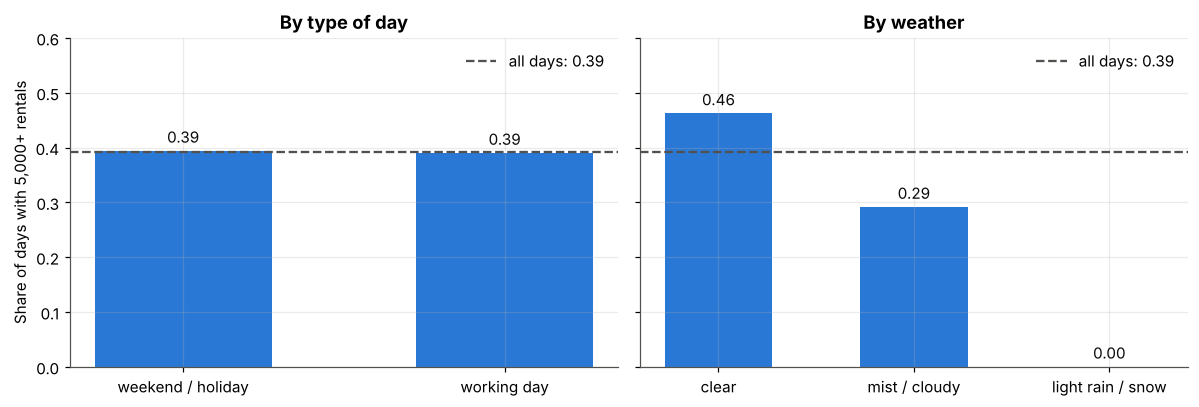

In [5]:
p_H = H.mean()
print(f"P(H) = {p_H:.3f} | P(H) x P(W) = {p_H * W.mean():.4f} vs P(H and W) = {(H & W).mean():.4f}")

day_type = days["workingday"].map({0: "weekend / holiday", 1: "working day"})
weather_names = {1: "clear", 2: "mist / cloudy", 3: "light rain / snow"}
weather = pd.Categorical(days["weathersit"].map(weather_names),
                         categories=list(weather_names.values()), ordered=True)

for name, groups in [("day type", day_type), ("weather", weather)]:
    summary = H.groupby(groups, observed=True).agg(busy_days="sum", days="count", rate="mean")
    print(f"\nP(H | {name})\n", summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, groups, title in [(axes[0], day_type, "By type of day"), (axes[1], weather, "By weather")]:
    rates = H.groupby(groups, observed=True).mean()
    bars = ax.bar(rates.index, rates.values, color=BLUE, width=0.55)
    ax.bar_label(bars, labels=[f"{r:.2f}" for r in rates], padding=3, color=INK)
    ax.axhline(p_H, color=MUTED, linestyle="--", linewidth=1.5, label=f"all days: {p_H:.2f}")
    ax.set(title=title, ylim=(0, 0.6))
    ax.legend(loc="upper right", frameon=False)
axes[0].set_ylabel("Share of days with 5,000+ rentals")
fig.tight_layout()
plt.show()

**Reading the chart.** The dashed line is P(H) for all days. A bar at the same height means "knowing this does not change the chance"; a bar far from the line means the two are linked.

- **Day type:** 0.39 versus 0.39. Knowing it is a working day hardly changes the chance of a busy day. In these records H and W behave almost **independently** (0.2668 versus 0.2676 on the product check).
- **Weather:** 0.46 on clear days, 0.29 on misty days, and 0 of the 21 rainy or snowy days. Weather and demand are strongly **dependent**.

> **Business meaning.** Do not plan the extra truck from the calendar: working days are no more likely to be busy than other days. Plan it from the **weather forecast**, which shifts the chance from 46% to almost nil. The calendar still matters for *who* rides: casual riders average 1,371 a day on weekends and holidays but 607 on working days (see `s7_rider_mix.py` below), so weekend campaigns aimed at casual users make sense even though total demand is similar.

> **Watch out.** These are associations in 2011–2012 records, not proof of cause. Rainy days are also more common in some seasons, so part of the weather gap may come from the season. Close rates suggest a weak link; they do not prove independence.

**Mutually exclusive is not independent.** "Working day" and "weekend or holiday" can never happen on the same day: they are mutually exclusive, so P(W and not W) = 0. But if you know a day is a working day, you know for certain it is not a weekend, so they are strongly *dependent*. Exclusive is about overlap; independence is about information.

In [6]:
print(days.groupby(day_type)[["casual", "registered"]].mean().round())

                   casual  registered
workingday                           
weekend / holiday  1371.0      2959.0
working day         607.0      3978.0


### Quick check (slide 54)

1. In the café table, 24 of the 40 rainy days sold out. What is P(S | R), and what is the denominator?
2. P(A) = 0.5, P(B) = 0.4 and P(A and B) = 0.2. Find P(A or B). Are A and B independent?
3. "Events that cannot happen together must be independent." True or false? Explain with working days.

Answers are in the appendix.

## Part 8 · Distributions: what does the full range of days look like?

A **distribution** tells us which values occur and how often. Keep three kinds apart:

| Kind | Described by | Simple example |
| --- | --- | --- |
| Discrete model | a probability for each separate value (PMF) | number of heads in 2 coin tosses |
| Continuous model | a smooth density curve; probability = area over an interval | the normal curve |
| Observed data | a histogram, box plot or violin plot of what actually happened | 731 daily rental counts |

Models are planning tools. Whether a model fits the real data is something we **check**, never assume.

In [7]:
import itertools

tosses = list(itertools.product("HT", repeat=2))        # HH, HT, TH, TT
heads = pd.Series([t.count("H") for t in tosses])
print(tosses)
print(heads.value_counts(normalize=True).sort_index())

[('H', 'H'), ('H', 'T'), ('T', 'H'), ('T', 'T')]
0    0.25
1    0.50
2    0.25
Name: proportion, dtype: float64


A PMF gives each value a probability between 0 and 1, and the probabilities add to 1 (1/4 + 1/2 + 1/4). One head is the most likely outcome because two of the four sequences (HT, TH) produce it.

### 8.1 Seeing a distribution: box plot and violin plot

A histogram shows a distribution, but two other pictures make **centre, spread and unusual values** easier to explain to a non-technical audience.

**Box plot.** The box spans Q1 to Q3, so it holds the middle 50% of days. The line inside is the median. The whiskers reach the furthest days that are within 1.5 × IQR of the box. Any dot beyond a whisker is an **unusual day** worth a second look (not automatically an error).

**Violin plot.** A box plot plus a smoothed histogram turned on its side. The **width** at any height shows how many days had that value: wide = common, thin = rare. The dashed lines inside mark Q1, the median and Q3.

On both we add the four numbers learners already know:

| Marker | Statistic | What it tells the manager |
| --- | --- | --- |
| white dot | median | the middle day: half the days were lower, half higher |
| orange diamond with bar | mean ± 1 SD | the balance point, and a typical distance from it |
| green star | mode | the most common level of demand |

**A note on the mode.** Daily counts are almost all different, so the plain mode is useless here: `cnt.mode()` returns several values that each occur only twice. For counts and measurements we use the **most common band** instead (for example 4,500–4,999 rentals), which is the tallest bar of a histogram.

In [8]:
def summarise(s, band=500):
    """Centre, spread and shape of a numeric column. Mode = middle of the most common band."""
    band_start = (s // band) * band               # e.g. 4,512 -> 4,500
    mode_start = band_start.mode().iloc[0]
    return pd.Series({
        "mean": s.mean(),
        "median": s.median(),
        "mode": mode_start + band / 2,            # centre of the most common band
        "SD": s.std(ddof=0),
        "Q1": s.quantile(0.25),
        "Q3": s.quantile(0.75),
        "skew": s.skew(),
    })

plain_mode = cnt.mode()
print(f"Plain mode of cnt: {len(plain_mode)} values tie, each seen only "
      f"{cnt.value_counts().max()} times")
print(pd.DataFrame({"cnt": summarise(cnt, 500), "casual": summarise(days["casual"], 250)}).round(2))

Plain mode of cnt: 35 values tie, each seen only 2 times


            cnt   casual
mean    4504.35   848.18
median  4548.00   713.00
mode    4750.00   125.00
SD      1935.89   686.15
Q1      3152.00   315.50
Q3      5956.00  1096.00
skew      -0.05     1.27


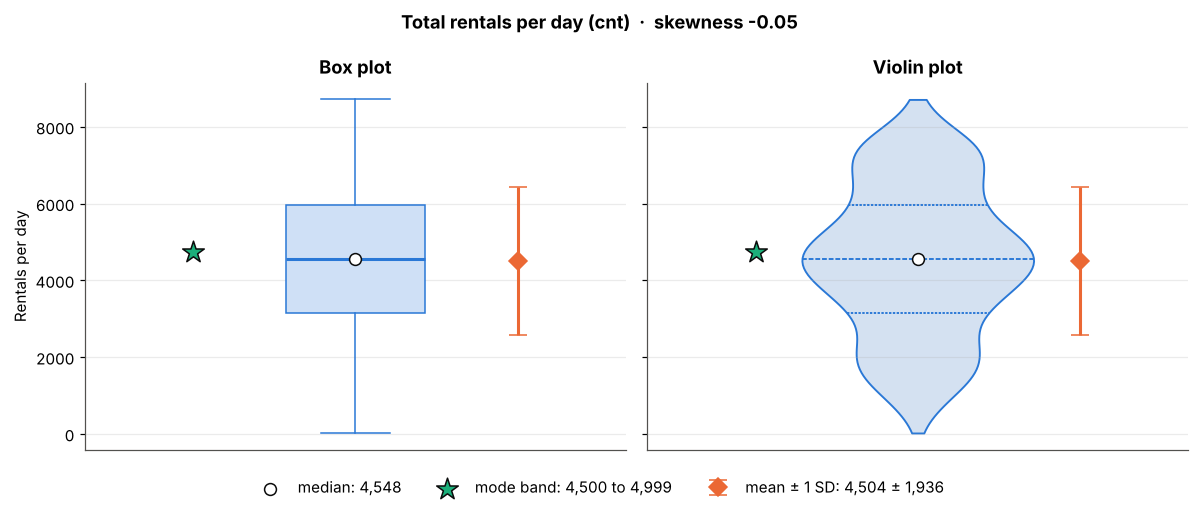

In [9]:
def plot_box_violin(s, label, band=500):
    """Box plot and violin plot of one column, marked with mean, SD, median and mode."""
    st = summarise(s, band)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)

    axes[0].boxplot(s, positions=[0], widths=0.36, patch_artist=True,
                    boxprops=dict(facecolor=LIGHT_BLUE, edgecolor=BLUE),
                    whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE),
                    medianprops=dict(color=BLUE, linewidth=2),
                    flierprops=dict(marker="o", markersize=4, markerfacecolor=BLUE,
                                    markeredgecolor="none", alpha=0.6))
    sns.violinplot(y=s, ax=axes[1], color=LIGHT_BLUE, linecolor=BLUE,
                   inner="quart", cut=0, width=0.6)

    for ax in axes:
        ax.errorbar(0.42, st["mean"], yerr=st["SD"], fmt="D", color=ORANGE, markersize=8,
                    capsize=6, linewidth=2, label=f"mean ± 1 SD: {st['mean']:,.0f} ± {st['SD']:,.0f}")
        ax.scatter(0, st["median"], s=60, color="white", edgecolor=INK, zorder=5,
                   label=f"median: {st['median']:,.0f}")
        ax.scatter(-0.42, st["mode"], marker="*", s=220, color=AQUA, edgecolor=INK, zorder=5,
                   label=f"mode band: {st['mode'] - band / 2:,.0f} to {st['mode'] + band / 2 - 1:,.0f}")
        ax.set(xlim=(-0.7, 0.7), xticks=[])
    axes[0].set(title="Box plot", ylabel="Rentals per day")
    axes[1].set(title="Violin plot", ylabel="")

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False)
    fig.suptitle(f"{label}  ·  skewness {st['skew']:.2f}", fontweight="bold")
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    plt.show()
    return st

cnt_stats = plot_box_violin(cnt, "Total rentals per day (cnt)")

**Reading the chart.** The box sits roughly in the middle of the whiskers, the violin is wide and fairly even top to bottom, and mean (4,504), median (4,548) and mode band (4,500–4,999) almost coincide. That is a **broad, roughly balanced** distribution (skewness −0.05). The whiskers reach the lowest day (22) and the highest (8,714), and no dot lies beyond them: no day is far enough out to be flagged by the 1.5 × IQR rule. The violin has two gentle bulges, a hint that the 731 days mix two groups (2011 was much quieter than 2012).

> **Business meaning.** A "typical" day sits near 4,500 rentals, and the middle half of days needed between 3,152 and 5,956 bikes. That range (the box) is the right basis for **day-to-day staffing**. The SD bar says a day is often about 1,900 rentals away from the average, so a plan built on the average alone will be wrong most days. For **fleet size** look at the top of the whisker, not the mean: some days need almost twice the average number of bikes.

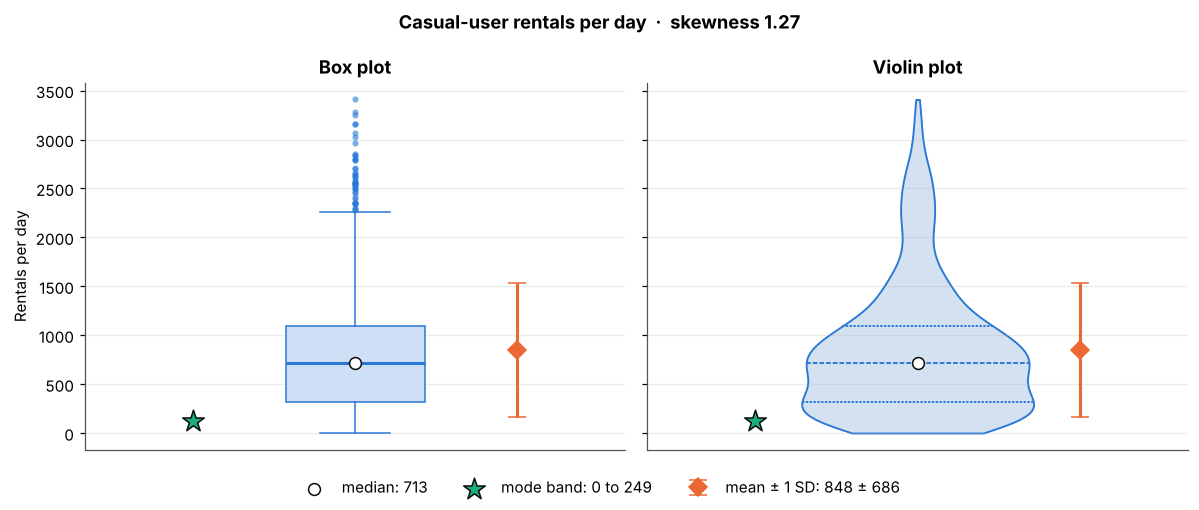

In [10]:
casual_stats = plot_box_violin(days["casual"], "Casual-user rentals per day", band=250)

**Reading the chart.** Now the picture is lopsided. The violin is fat at the bottom and has a long thin neck upwards; the box sits low; there is a row of dots above the upper whisker. The mode band (0–249) is below the median (713), which is below the mean (848). This order, **mode < median < mean**, is the signature of a **right-skewed** distribution (skewness 1.27): a few very busy days pull the mean up. (The violin's widest point sits a little above the star because the violin smooths the counts, while the star comes from exact 250-wide bands: 151 days had fewer than 250 casual rentals.)

> **Business meaning.** Casual riders (tourists and leisure users) are **spiky**: most days are quiet, but sunny weekends bring surges. For a "typical" casual day report the median (713), not the mean. For **peak planning** (extra bikes at tourist stations, pop-up staff) plan for the dots above the whisker, not the average. Casual users are also the pool for membership campaigns, so their peak days are the best days to promote memberships.

### 8.2 Comparing groups: one violin per season

Box and violin plots are at their most useful when we put groups side by side. Season codes are kept as codes (the source documents disagree on their names); the months each code covers in this file are shown under the label.

          mean  median     std   min   max
season                                    
1       2604.0  2209.0  1400.0   431  7836
2       4992.0  4942.0  1696.0   795  8362
3       5644.0  5354.0  1460.0  1115  8714
4       4728.0  4634.0  1700.0    22  8555


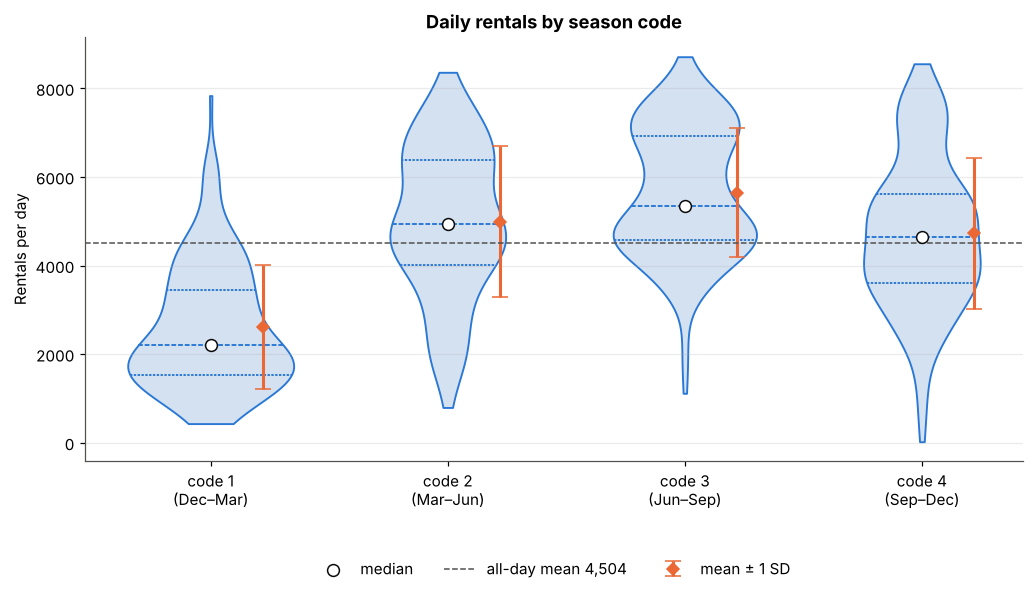

In [11]:
season_names = {1: "code 1\n(Dec–Mar)", 2: "code 2\n(Mar–Jun)",
                3: "code 3\n(Jun–Sep)", 4: "code 4\n(Sep–Dec)"}
by_season = days.groupby("season")["cnt"].agg(["mean", "median", "std", "min", "max"])
print(by_season.round(0))

fig, ax = plt.subplots(figsize=(11, 5))
sns.violinplot(data=days, x="season", y="cnt", color=LIGHT_BLUE, linecolor=BLUE,
               inner="quart", cut=0, width=0.7, ax=ax)
x = np.arange(len(by_season))
ax.errorbar(x + 0.22, by_season["mean"], yerr=by_season["std"], fmt="D", color=ORANGE,
            capsize=5, linewidth=2, label="mean ± 1 SD")
ax.scatter(x, by_season["median"], s=60, color="white", edgecolor=INK, zorder=5, label="median")
ax.axhline(cnt.mean(), color=MUTED, linestyle="--", linewidth=1,
           label=f"all-day mean {cnt.mean():,.0f}")
ax.set_xticks(x, [season_names[s] for s in by_season.index])
ax.set(xlabel="", ylabel="Rentals per day", title="Daily rentals by season code")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)
plt.show()

**Reading the chart.** Season code 1 (the cold months) sits far below the dashed all-day mean, with a median of about 2,200. Code 3 (summer) sits highest, with a median near 5,350: more than double. Code 4 has a long thin tail down to 22 rentals, a single extreme day. Within each season the SD is still 1,400–1,700, so the violins are tall: season tells you a lot, but not everything.

> **Business meaning.** Schedule **bike maintenance and staff leave in season code 1**, when a typical day needs less than half the bikes of summer. Plan **maximum fleet and the most rebalancing trucks for code 3**. Because the spread inside each season is still large, combine the season with the weather forecast (Part 7) for day-by-day decisions.

### 8.3 The normal curve and the 68–95–99.7 rule

**A simple real-life case.** A coffee factory fills 500 g bags. The machine is not perfect: fill weights follow roughly a **normal** (bell-shaped) curve with mean μ = 500 g and SD σ = 4 g. The quality manager asks: *what share of bags will weigh less than 492 g and have to be rejected?*

The normal curve is set by just two numbers: μ (where it is centred) and σ (how wide it is). For a continuous model, probability is the **area** under the curve over an interval. `norm.cdf(x, mu, sigma)` gives the area to the left of x.

In [12]:
mu, sigma = 500, 4                     # coffee bag weights in grams
print(f"P(bag < 492 g)        = {norm.cdf(492, mu, sigma):.4f}")
print(f"P(496 g <= bag <= 504 g) = {norm.cdf(504, mu, sigma) - norm.cdf(496, mu, sigma):.4f}")

for k in [1, 2, 3]:
    print(f"normal model, within {k} SD: {norm.cdf(k) - norm.cdf(-k):.2%}")

P(bag < 492 g)        = 0.0228
P(496 g <= bag <= 504 g) = 0.6827
normal model, within 1 SD: 68.27%
normal model, within 2 SD: 95.45%
normal model, within 3 SD: 99.73%


492 g is exactly 2 SDs below the mean, so about 2.3% of bags fall below it. The last three lines are the **68–95–99.7 rule**: in a normal model about 68% of values lie within 1 SD of the mean, 95% within 2 SDs and 99.7% within 3 SDs.

> **Business meaning.** If the rejection rate (2.3%) is too costly, the manager has two levers: move the mean up (more coffee per bag) or reduce the SD (a better machine). The normal model turns that trade-off into numbers. But it only works **if the data really are close to normal**, which is the next check.

Does the rule hold for real bike days? We compute every day's distance from the mean in SD units (its z-score, section 8.4) and count.

within 1 SD: normal says  68.3% | observed 443 of 731 = 60.6%
within 2 SD: normal says  95.4% | observed 721 of 731 = 98.6%
within 3 SD: normal says  99.7% | observed 731 of 731 = 100.0%


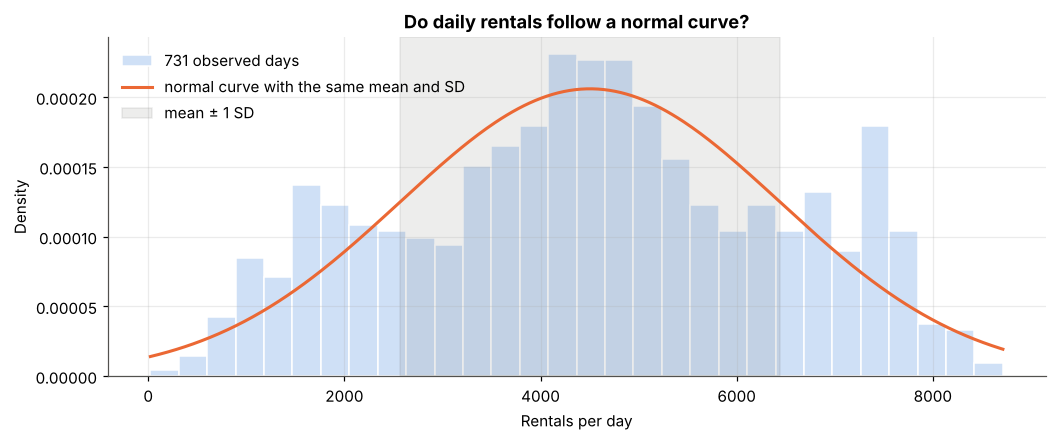

In [13]:
mu, sigma = cnt.mean(), cnt.std(ddof=0)
z = (cnt - mu) / sigma

for k in [1, 2, 3]:
    inside = (z.abs() <= k)
    print(f"within {k} SD: normal says {norm.cdf(k) - norm.cdf(-k):6.1%} | "
          f"observed {inside.sum()} of {len(cnt)} = {inside.mean():.1%}")

fig, ax = plt.subplots(figsize=(11, 4))
ax.hist(cnt, bins=30, density=True, color=LIGHT_BLUE, edgecolor="white", label="731 observed days")
grid = np.linspace(cnt.min(), cnt.max(), 300)
ax.plot(grid, norm.pdf(grid, mu, sigma), color=ORANGE, linewidth=2,
        label="normal curve with the same mean and SD")
ax.axvspan(mu - sigma, mu + sigma, color=MUTED, alpha=0.10, label="mean ± 1 SD")
ax.set(xlabel="Rentals per day", ylabel="Density", title="Do daily rentals follow a normal curve?")
ax.legend(frameon=False)
plt.show()

**Reading the chart.** The orange curve is what a normal distribution with the same mean and SD would look like. The real histogram is **flatter and wider in the middle** than the bell: fewer days sit close to the mean (60.6% within 1 SD, not 68%) and more sit in the "shoulders" between 1 and 2 SDs. The tails are *thinner* than normal: 98.6% of days are within 2 SDs and every day is within 3.

> **Business meaning.** A planner who assumed a normal curve would expect 68% of days between 2,568 and 6,440 rentals and be surprised more often than planned. Using the real data instead: a fleet ready for **mean + 2 SD ≈ 8,376 rentals would have covered 728 of 731 days**. Use the observed percentiles for planning, and use the normal model only after checking it fits.

### 8.4 z-scores: how unusual is one day?

z = (x − mean) ÷ SD says how many SDs a value sits above (+) or below (−) a stated reference mean. A coffee bag at 492 g has z = (492 − 500) ÷ 4 = −2. The sign gives the direction; the size gives the distance.

z-scores let us put very different things on one scale and build a simple **exception report**: list the days that sat more than 2 SDs from the mean.

In [14]:
days["z"] = (cnt - mu) / sigma

exceptions = (days.loc[days["z"].abs() > 2, ["dteday", "season", "weathersit", "cnt", "z"]]
                  .sort_values("z"))
print(f"{len(exceptions)} of {len(days)} days are more than 2 SDs from the mean\n")
exceptions["dteday"] = exceptions["dteday"].dt.date
print(exceptions.round({"z": 2}).to_string(index=False))

10 of 731 days are more than 2 SDs from the mean

    dteday  season  weathersit  cnt     z
2012-10-29       4           3   22 -2.32
2011-01-27       1           1  431 -2.10
2012-12-26       1           3  441 -2.10
2011-01-26       1           3  506 -2.07
2011-03-06       1           2  605 -2.01
2011-03-10       1           3  623 -2.00
2011-10-29       4           3  627 -2.00
2012-09-22       3           1 8395  2.01
2012-09-29       4           1 8555  2.09
2012-09-15       3           1 8714  2.17


**Reading the output.** The busiest day, 2012-09-15 with 8,714 rentals, has z = +2.17: about 2.2 SDs above the mean. The quietest, 2012-10-29 with 22 rentals (weather code 3), has z = −2.32; that is the day Hurricane Sandy reached the Washington area. The other low days are mostly rainy (weather code 3) or in the cold season code 1.

> **Business meaning.** A z-score report turns 731 rows into a short list a manager can review. High-z days show what peak demand looks like (plan fleet for them). Low-z days are often explained by storms or holidays: they are **real records, not errors**, and deleting them would make the system look more predictable than it is.

> **Watch out.** A z-score is a position, not a percentile. z = +2.17 does not mean "the top 1.5% of days" unless the data are normal, and we have just seen they are not.

## Part 9 · Sample means and the Central Limit Theorem

**A simple real-life case.** A new branch manager wants to know if a promotion is working. One day's takings jump around a lot: a rainy Tuesday and a payday Friday look like different businesses. But the **average over a month** barely moves from one month to the next. Averages are steadier than single days. This part measures *how much* steadier.

Three levels, kept apart:

1. **Raw values**: the 731 observed days, each with its own count.
2. **One sample mean**: pick n days, average them, get one number x̄.
3. **The sampling distribution**: repeat step 2 thousands of times and look at all the x̄ values together.

**Tiny example.** Draw two values (with replacement) from the flat set {5, 10, 15, 20, 25} and average them. There are 25 equally likely pairs. Only one pair gives a mean of 5 (5, 5), but five pairs give 15. The means pile up in the middle, and their SD is 5 instead of the raw 7.07 (7.07 ÷ √2). **Averaging narrows the spread.**

Now with the real days: we draw 2,000 samples of 5 days and 2,000 samples of 50 days, and keep each sample's mean.

In [15]:
rng = np.random.default_rng(1516)                       # fixed seed: same result every run
values = cnt.to_numpy()

means_5 = rng.choice(values, size=(2000, 5)).mean(axis=1)    # 2,000 rows of 5 days -> 2,000 means
means_50 = rng.choice(values, size=(2000, 50)).mean(axis=1)

sigma = values.std()
results = pd.DataFrame({
    "what": ["731 real days", "means of 5 days", "means of 50 days"],
    "mean": [values.mean(), means_5.mean(), means_50.mean()],
    "SD": [sigma, means_5.std(), means_50.std()],
    "formula sigma / sqrt(n)": [sigma, sigma / np.sqrt(5), sigma / np.sqrt(50)],
})
print(results.round(0).to_string(index=False))

            what   mean     SD  formula sigma / sqrt(n)
   731 real days 4504.0 1936.0                   1936.0
 means of 5 days 4534.0  847.0                    866.0
means of 50 days 4514.0  266.0                    274.0


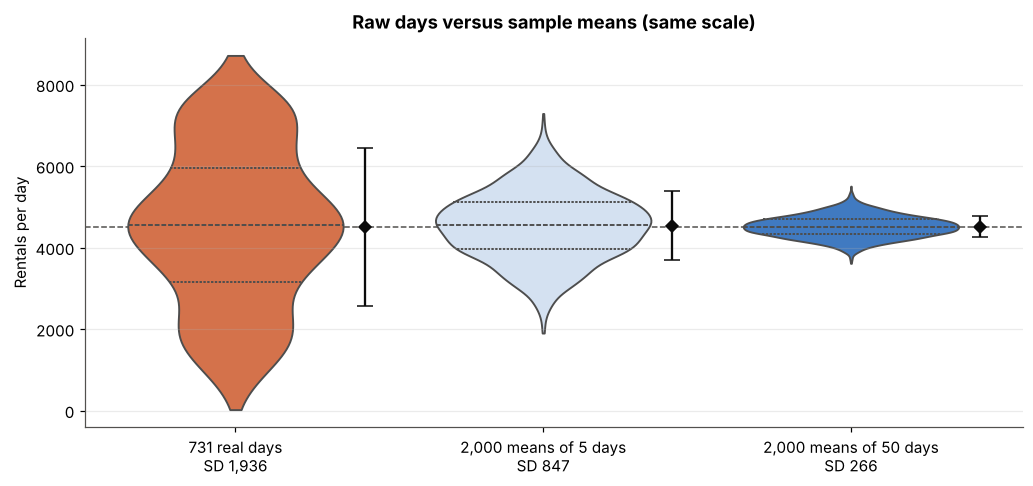

In [16]:
groups = {"731 real days": values,
          "2,000 means of 5 days": means_5,
          "2,000 means of 50 days": means_50}
labels = [f"{name}\nSD {v.std():,.0f}" for name, v in groups.items()]
long = pd.concat([pd.DataFrame({"what": k, "rentals": v}) for k, v in groups.items()])

fig, ax = plt.subplots(figsize=(11, 4.6))
sns.violinplot(data=long, x="what", y="rentals", hue="what", legend=False,
               palette=[ORANGE, LIGHT_BLUE, BLUE], inner="quart", cut=0, width=0.7, ax=ax)
for i, v in enumerate(groups.values()):
    ax.errorbar(i + 0.42, v.mean(), yerr=v.std(), fmt="D", color=INK, capsize=5)  # mean ± 1 SD
ax.axhline(values.mean(), color=MUTED, linestyle="--", linewidth=1, zorder=0)
ax.set_xticks(range(3), labels)
ax.set(xlabel="", ylabel="Rentals per day", title="Raw days versus sample means (same scale)")
plt.show()

**Reading the chart.** All three violins are centred on the same dashed line, the frame mean of 4,504. The orange violin is the real days. The black diamond and bar beside each violin mark its mean ± 1 SD, and the SD is printed under each label: tall and wide, from 22 to 8,714. The means of 5 days are squeezed into a much shorter violin, and the means of 50 days into a short, narrow one. The SD shrinks from 1,936 to about 847 and then 266, close to the formula **σ ÷ √n** (866 and 274). Multiplying n by 4 halves the SD; 10 times the days gives about √10 ≈ 3.2 times tighter means. The simulated values are not exactly the formula because 2,000 repetitions have their own chance variation.

> **Business meaning.** Suppose a promotion is tested and the manager compares average daily rentals before and after. Judged on **5 days**, the average could easily be off by about ±850 rentals just by chance, so a real effect of +500 would be invisible. Judged on **50 days**, chance noise is about ±270, so a +500 effect starts to stand out. This is why A/B tests and pilots need enough days, and it is the question Session 16 answers properly.

**The CLT in careful words.** Under suitable conditions (independent draws from a distribution with a finite variance), the distribution of sample means becomes more nearly normal as n grows, and its SD shrinks like σ ÷ √n.

| It is true that | It is **not** true that |
| --- | --- |
| it describes the **means** | the raw daily counts become normal |
| larger n gives steadier means | there is a magic n (such as 30): skewed data like `casual` need a larger n |
| random samples centre on the truth | it fixes bias: 50 badly chosen days cluster tightly around the **wrong** centre |
| the simulation resamples the observed days | it creates new days or predicts next year: dated days are not independent draws |

## Part 10 · Claims: what can an analyst honestly say?

### Checkpoint 2 · try it yourself

Use the notebook results above. Answers are in the appendix.

- **C2.1 Shape.** Is `cnt` strongly skewed or broad and balanced? Which summary pair would you report? Name one extreme day without calling it an error.
- **C2.2 Events.** With H: `cnt >= 5000` and W: `workingday == 1`, state the four cell counts and the denominator of P(H) and of P(H | W).
- **C2.3 Position.** Compute z for 2012-09-15. Is it above or below the mean, and by how many SDs? Does z give a percentile?
- **C2.4 Display.** In the CLT violin plot, which violin shows real days and which show means? Why do the means still vary?
- **C2.5 Analyst's note.** Write 4–6 sentences: scope and a typical value; a spread measure and the shape; P(H | W) with its denominator; a selection caveat; one question for later inference.

In [17]:
# Your answers here: use the variables already defined above (cnt, H, W, days["z"], means_5, means_50)

### A worked analyst's note

> **Analyst's note.** Across the 731 observed Capital Bikeshare days in 2011–2012, a typical day had about 4,500 rentals (mean 4,504, median 4,548). Variation was large: the SD was about 1,936 rentals, the middle half of days ran from 3,152 to 5,956, and counts ranged from 22 to 8,714; the box and violin plots show a broad, roughly balanced shape, with cold-season days far quieter than summer days. High demand (5,000 or more rentals) occurred on 195 of 500 working days (0.39), almost the same as on other days, while no rainy or snowy day reached it. Selecting only the first 50 dates would overweight winter days, and even a well-drawn sample varies by chance. These figures describe this system and period, not guaranteed future demand. Next question: how sure can we be when a sample of days is used to estimate a wider group of days?

### Eight statements to question

| Statement | Better |
| --- | --- |
| "P(A \| B) equals P(B \| A)." | different denominators, different questions (0.39 versus 0.68 above) |
| "Exclusive events are independent." | they are strongly dependent: one rules out the other |
| "Similar rates prove there is no link." | close rates suggest a weak link in these records; they prove nothing about cause |
| "The mode of a count is the most common value." | for counts and measurements use the most common band |
| "A z-score means the data are normal." | it only measures distance in SD units; check the shape first |
| "68% of any data lie within 1 SD." | only for a normal model; bike days gave 60.6% |
| "The CLT makes the data normal." | it describes sample means, under conditions, with no magic n |
| "A bigger sample fixes a biased one." | more badly chosen days are still badly chosen |

**Next session (16):** quantifying how confident we can be that a sampled pattern extends beyond the observed days.

## Appendix · Answers

**Quick check (slide 54).**

1. P(S | R) = 24 ÷ 40 = 0.60. The denominator is the 40 rainy days.
2. P(A or B) = 0.5 + 0.4 − 0.2 = 0.7. Independent, because P(A) × P(B) = 0.5 × 0.4 = 0.2 = P(A and B).
3. False. "Working day" and "not a working day" can never happen together, yet knowing one tells you for certain the other did not happen: P(W | not W) = 0 while P(W) = 0.68. They are dependent.

**Checkpoint 2.**

- **C2.1** Broad and roughly balanced (skewness −0.05, mean ≈ median ≈ mode band). Report the mean with SD (4,504 ± 1,936) or the median with IQR (4,548; 2,804), plus the range 22 to 8,714. 2012-09-15 (8,714) is the observed maximum, a real record.
- **C2.2** not W & not H 140, not W & H 91, W & not H 305, W & H 195. P(H) = 286 ÷ 731 = 0.3912 (all days); P(H | W) = 195 ÷ 500 = 0.3900 (working days only).
- **C2.3** z = (8,714 − 4,504.35) ÷ 1,935.89 ≈ +2.17: about 2.2 SDs above the mean. It is a position, not a percentile, because the days are not normal.
- **C2.4** Orange = 731 real days; the two blue violins = 2,000 sample means each. Every sample draws different days, so each mean differs; the n = 50 means cluster more tightly (SD ≈ 266 versus 847) but do not all equal the frame mean.
- **C2.5** See the worked note.

*Data: Fanaee-T, H. (2013). Bike Sharing [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5W894. CC BY 4.0.*